# Étape 6 — Comparaison CAH et DBSCAN

Ce notebook compare une Classification Ascendante Hiérarchique (CAH) et DBSCAN sur les six variables préparées par `log1p + StandardScaler`. Les résultats K-Means existants sont réutilisés pour la comparaison, sans modifier ni réentraîner son modèle final.

Attention : pour DBSCAN, la silhouette est calculée uniquement sur les observations non bruitées. Elle est donc accompagnée du nombre de points évalués et du taux de couverture.

## 1. Chargement commun

Les six dépenses sont les seules variables utilisées dans les distances. `Channel`, `Region` et `customer_index` sont conservées pour l'interprétation, mais ne participent pas à l'apprentissage.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score

sns.set_theme(style='whitegrid', context='notebook')
project_root = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
prepared_path = project_root / 'data' / 'processed' / 'customers_log_standard_scaled.csv'
raw_path = project_root / 'data' / 'raw' / 'Wholesale customers data.csv'
figures_dir = project_root / 'results' / 'figures'
tables_dir = project_root / 'results' / 'tables'
figures_dir.mkdir(parents=True, exist_ok=True); tables_dir.mkdir(parents=True, exist_ok=True)
FEATURES = ['Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']
X = pd.read_csv(prepared_path, index_col='customer_index')
raw = pd.read_csv(raw_path)
assert X.shape == (440, 6) and list(X.columns) == FEATURES
assert np.isfinite(X.to_numpy()).all() and not X.isna().any().any()
assert raw.shape[0] == X.shape[0]
print(f'Données utilisées : {X.shape[0]} clients, {X.shape[1]} variables.')

Données utilisées : 440 clients, 6 variables.


## 2. Résultats K-Means de référence

Le modèle K-Means final déjà entraîné est lu depuis ses labels sauvegardés. Les numéros de clusters sont des identifiants propres à chaque méthode et ne doivent pas être comparés directement.

In [2]:
kmeans_labels = pd.read_csv(tables_dir / 'kmeans_client_labels.csv', index_col='customer_index')['cluster']
assert len(kmeans_labels) == len(X) and kmeans_labels.index.equals(X.index)
kmeans_silhouette = silhouette_score(X, kmeans_labels)
kmeans_sizes = kmeans_labels.value_counts().sort_index()
print(f'K-Means : {kmeans_labels.nunique()} clusters, silhouette={kmeans_silhouette:.4f}, tailles={kmeans_sizes.tolist()}')

K-Means : 2 clusters, silhouette=0.2903, tailles=[252, 188]


## 3. Classification Ascendante Hiérarchique

La CAH `ward` fusionne progressivement les groupes en minimisant l'augmentation de variance intra-groupe. Nous testons K=2 à K=6 et commençons par K=2, car cela permet une comparaison directe avec K-Means.

In [3]:
cah_rows = []
cah_labels_by_k = {}
for k in range(2, 7):
    model = AgglomerativeClustering(n_clusters=k, linkage='ward')
    labels = model.fit_predict(X)
    sizes = pd.Series(labels).value_counts().sort_index()
    cah_labels_by_k[k] = labels
    cah_rows.append({'K': k, 'Silhouette': silhouette_score(X, labels), 'Tailles_clusters': ', '.join(str(int(v)) for v in sizes), 'Taille_min': int(sizes.min()), 'Taille_max': int(sizes.max())})
cah_results = pd.DataFrame(cah_rows)
best_cah_k = int(cah_results.loc[cah_results['Silhouette'].idxmax(), 'K'])
best_cah_labels = cah_labels_by_k[best_cah_k]
display(cah_results.round({'Silhouette': 4}))
print(f'Meilleur K CAH selon la silhouette : {best_cah_k}')
cah_results.to_csv(tables_dir / 'cah_search_metrics.csv', index=False)

,K,Silhouette,Tailles_clusters,Taille_min,Taille_max
0,2,0.2585,"178, 262",178,262
1,3,0.2547,"262, 53, 125",53,262
2,4,0.2021,"53, 208, 125, 54",53,208
3,5,0.2025,"208, 18, 125, 54, 35",18,208
4,6,0.1707,"125, 18, 150, 54, 35, 58",18,150


Meilleur K CAH selon la silhouette : 2


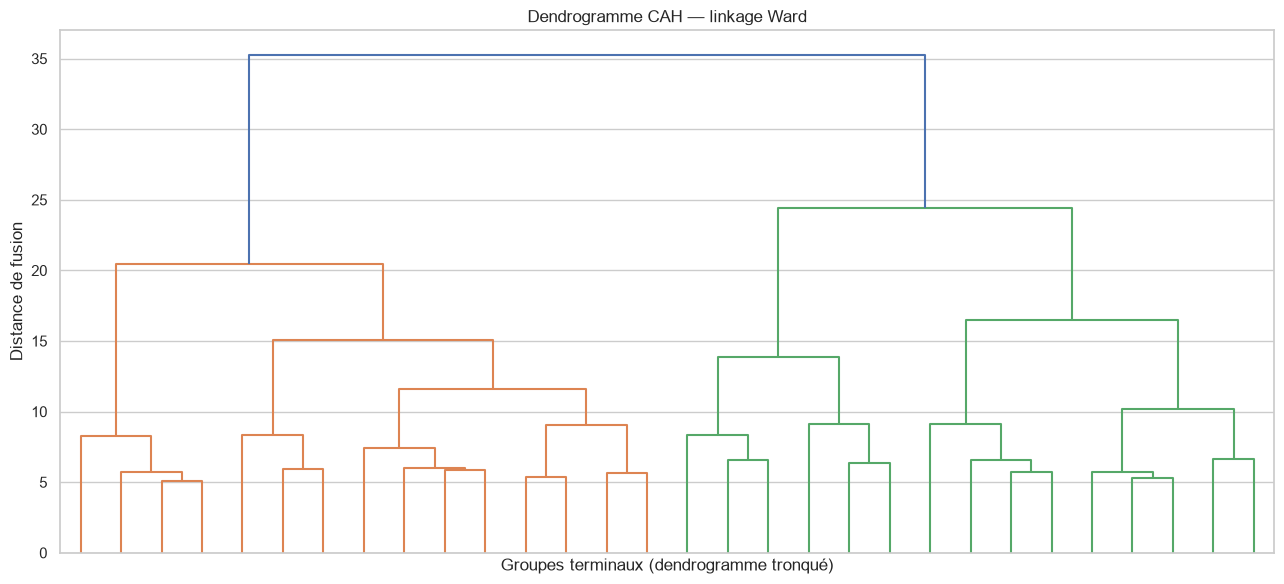

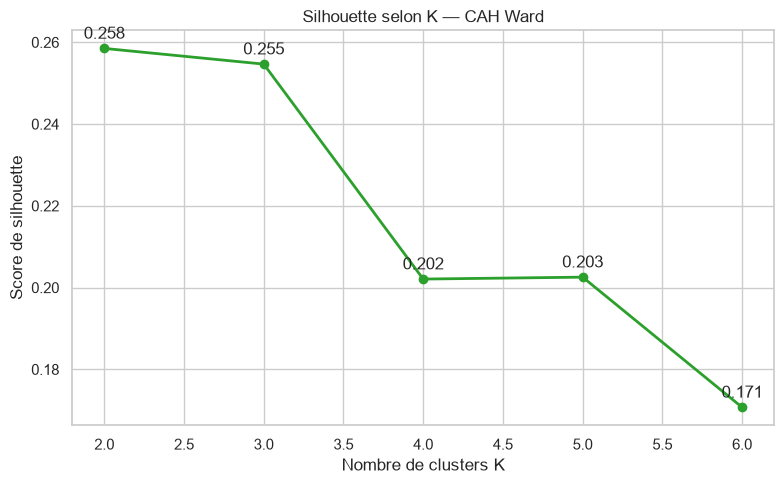

In [4]:
Z = linkage(X, method='ward')
fig, ax = plt.subplots(figsize=(13, 6))
dendrogram(Z, truncate_mode='lastp', p=30, leaf_rotation=90, leaf_font_size=8, no_labels=True, ax=ax)
ax.set(title='Dendrogramme CAH — linkage Ward', xlabel='Groupes terminaux (dendrogramme tronqué)', ylabel='Distance de fusion')
fig.tight_layout(); fig.savefig(figures_dir / '14_cah_dendrogramme_ward.png', dpi=180, bbox_inches='tight'); plt.show(); plt.close(fig)
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(cah_results['K'], cah_results['Silhouette'], marker='o', linewidth=2, color='#2ca02c')
for _, row in cah_results.iterrows(): ax.annotate(f"{row['Silhouette']:.3f}", (row['K'], row['Silhouette']), textcoords='offset points', xytext=(0, 7), ha='center')
ax.set(title='Silhouette selon K — CAH Ward', xlabel='Nombre de clusters K', ylabel='Score de silhouette')
fig.tight_layout(); fig.savefig(figures_dir / '15_cah_silhouette.png', dpi=180, bbox_inches='tight'); plt.show(); plt.close(fig)

## 4. DBSCAN

DBSCAN regroupe les points suffisamment denses. `eps` définit le voisinage, `min_samples` le nombre minimal de voisins pour former une zone dense, et le label -1 désigne le bruit. Contrairement à K-Means et à la CAH, DBSCAN peut laisser certains clients sans cluster.

In [5]:
eps_values = [0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 1.00, 1.20]
min_samples_values = [5, 10]
dbscan_rows = []
dbscan_labels_by_config = {}
for eps in eps_values:
    for min_samples in min_samples_values:
        model = DBSCAN(eps=eps, min_samples=min_samples)
        labels = model.fit_predict(X)
        key = (eps, min_samples)
        dbscan_labels_by_config[key] = labels
        noise = int(np.sum(labels == -1))
        valid = labels != -1
        n_clusters = len(set(labels[valid]))
        valid_points = int(valid.sum())
        score = silhouette_score(X.loc[valid], labels[valid]) if n_clusters >= 2 and valid_points > n_clusters else np.nan
        sizes = pd.Series(labels[valid]).value_counts().sort_index()
        dbscan_rows.append({'eps': eps, 'min_samples': min_samples, 'Nombre_clusters': n_clusters, 'Bruit': noise, 'Bruit_pct': 100 * noise / len(X), 'Points_evalues': valid_points, 'Couverture_pct': 100 * valid_points / len(X), 'Silhouette_sans_bruit': score, 'Tailles_clusters': ', '.join(str(int(v)) for v in sizes)})
dbscan_results = pd.DataFrame(dbscan_rows)
display(dbscan_results.round({'Bruit_pct': 2, 'Couverture_pct': 2, 'Silhouette_sans_bruit': 4}))
dbscan_results.to_csv(tables_dir / 'dbscan_grid_metrics.csv', index=False)

,eps,min_samples,Nombre_clusters,Bruit,Bruit_pct,Points_evalues,Couverture_pct,Silhouette_sans_bruit,Tailles_clusters
0,0.3,5,0,440,100.00,0,0.00,NaN,
1,0.3,10,0,440,100.00,0,0.00,NaN,
2,0.4,5,0,440,100.00,0,0.00,NaN,
3,0.4,10,0,440,100.00,0,0.00,NaN,
4,0.5,5,1,435,98.86,5,1.14,NaN,5
5,0.5,10,0,440,100.00,0,0.00,NaN,
6,0.6,5,7,385,87.50,55,12.50,0.3606,"20, 9, 5, 8, 5, 5, 3"
7,0.6,10,0,440,100.00,0,0.00,NaN,
8,0.7,5,4,343,77.95,97,22.05,0.3640,"54, 23, 11, 9"
9,0.7,10,1,422,95.91,18,4.09,NaN,18


### Choix transparent d'une configuration DBSCAN

Une configuration DBSCAN est considérée comme exploitable si elle forme au moins deux clusters, conserve au moins 70 % des clients et fournit une silhouette calculable. Cette règle limite le risque de sélectionner un score élevé obtenu après exclusion de presque tous les clients.

In [6]:
dbscan_candidates = dbscan_results[(dbscan_results['Nombre_clusters'] >= 2) & (dbscan_results['Couverture_pct'] >= 70) & dbscan_results['Silhouette_sans_bruit'].notna()].copy()
dbscan_satisfactory = not dbscan_candidates.empty
if dbscan_satisfactory:
    chosen_dbscan_row = dbscan_candidates.sort_values(['Silhouette_sans_bruit', 'Couverture_pct'], ascending=False).iloc[0]
else:
    valid_configs = dbscan_results[(dbscan_results['Nombre_clusters'] >= 2) & dbscan_results['Silhouette_sans_bruit'].notna()].copy()
    chosen_dbscan_row = valid_configs.sort_values(['Couverture_pct', 'Silhouette_sans_bruit'], ascending=False).iloc[0] if not valid_configs.empty else dbscan_results.iloc[0]
chosen_key = (float(chosen_dbscan_row['eps']), int(chosen_dbscan_row['min_samples']))
chosen_dbscan_labels = dbscan_labels_by_config[chosen_key]
print(f"Configuration retenue pour l'analyse : eps={chosen_key[0]:.2f}, min_samples={chosen_key[1]}")
print(f"Clusters={int(chosen_dbscan_row['Nombre_clusters'])}, bruit={chosen_dbscan_row['Bruit_pct']:.2f} %, couverture={chosen_dbscan_row['Couverture_pct']:.2f} %, silhouette sans bruit={chosen_dbscan_row['Silhouette_sans_bruit']:.4f}")
print('DBSCAN offre une partition satisfaisante selon la règle fixée.' if dbscan_satisfactory else 'Aucune configuration ne satisfait simultanément les critères de couverture et de séparation ; DBSCAN doit être interprété avec prudence.')

Configuration retenue pour l'analyse : eps=0.80, min_samples=5
Clusters=3, bruit=52.27 %, couverture=47.73 %, silhouette sans bruit=0.2885
Aucune configuration ne satisfait simultanément les critères de couverture et de séparation ; DBSCAN doit être interprété avec prudence.


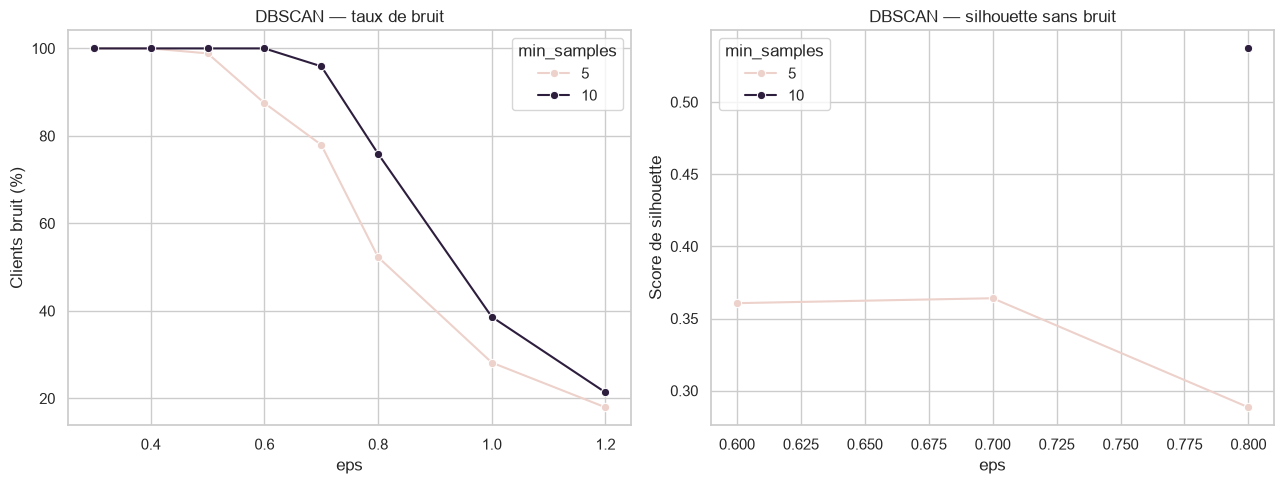

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.lineplot(data=dbscan_results, x='eps', y='Bruit_pct', hue='min_samples', marker='o', ax=axes[0])
axes[0].set(title='DBSCAN — taux de bruit', xlabel='eps', ylabel='Clients bruit (%)')
sns.lineplot(data=dbscan_results, x='eps', y='Silhouette_sans_bruit', hue='min_samples', marker='o', ax=axes[1])
axes[1].set(title='DBSCAN — silhouette sans bruit', xlabel='eps', ylabel='Score de silhouette')
fig.tight_layout(); fig.savefig(figures_dir / '16_dbscan_grid_results.png', dpi=180, bbox_inches='tight'); plt.show(); plt.close(fig)

## 5. Comparaison globale

Les scores K-Means et CAH utilisent les 440 clients. Le score DBSCAN est indiqué avec le nombre de points effectivement évalués et sa couverture ; il ne doit pas être lu comme strictement équivalent si des clients sont bruités.

,Méthode,Clusters,Silhouette,Points_evalues,Couverture_pct,Bruit_pct,Effectifs,Avantages_limites
0,K-Means,2,0.2903,440,100.00,0.00,"252, 188",Simple et reproductible ; nécessite K et préfè...
1,CAH Ward,2,0.2585,440,100.00,0.00,"178, 262",Dendrogramme interprétable ; coût et choix de ...
2,DBSCAN,3,0.2885,210,47.73,52.27,"200, 5, 5",Détecte le bruit et des formes denses ; sensib...


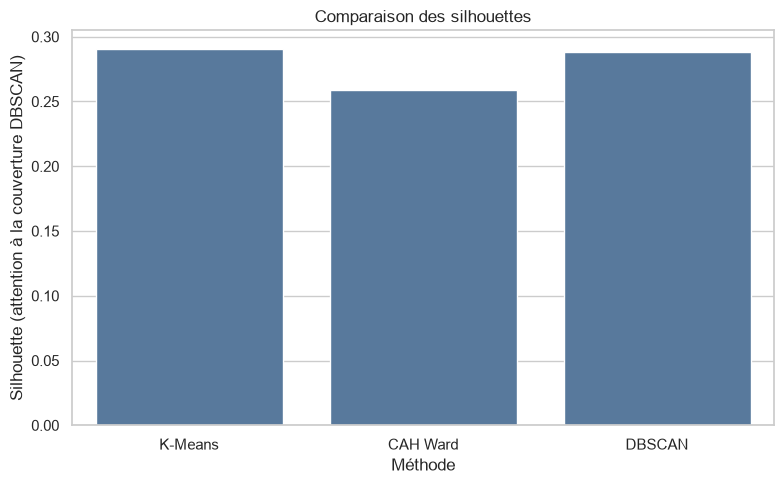

In [8]:
cah_sizes = pd.Series(best_cah_labels).value_counts().sort_index()
chosen_dbscan_valid = chosen_dbscan_labels != -1
comparison = pd.DataFrame([
    {'Méthode': 'K-Means', 'Clusters': int(kmeans_labels.nunique()), 'Silhouette': kmeans_silhouette, 'Points_evalues': len(X), 'Couverture_pct': 100.0, 'Bruit_pct': 0.0, 'Effectifs': ', '.join(map(str, kmeans_sizes.tolist())), 'Avantages_limites': 'Simple et reproductible ; nécessite K et préfère des groupes compacts.'},
    {'Méthode': 'CAH Ward', 'Clusters': int(best_cah_k), 'Silhouette': float(cah_results.loc[cah_results['K'] == best_cah_k, 'Silhouette'].iloc[0]), 'Points_evalues': len(X), 'Couverture_pct': 100.0, 'Bruit_pct': 0.0, 'Effectifs': ', '.join(map(str, cah_sizes.tolist())), 'Avantages_limites': 'Dendrogramme interprétable ; coût et choix de K à surveiller.'},
    {'Méthode': 'DBSCAN', 'Clusters': int(chosen_dbscan_row['Nombre_clusters']), 'Silhouette': float(chosen_dbscan_row['Silhouette_sans_bruit']) if pd.notna(chosen_dbscan_row['Silhouette_sans_bruit']) else np.nan, 'Points_evalues': int(chosen_dbscan_row['Points_evalues']), 'Couverture_pct': float(chosen_dbscan_row['Couverture_pct']), 'Bruit_pct': float(chosen_dbscan_row['Bruit_pct']), 'Effectifs': chosen_dbscan_row['Tailles_clusters'], 'Avantages_limites': 'Détecte le bruit et des formes denses ; sensible à eps et min_samples.'}
])
display(comparison.round({'Silhouette': 4, 'Couverture_pct': 2, 'Bruit_pct': 2}))
comparison.to_csv(tables_dir / 'comparison_kmeans_cah_dbscan.csv', index=False)
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=comparison, x='Méthode', y='Silhouette', ax=ax, color='#4c78a8')
ax.set(title='Comparaison des silhouettes', ylabel='Silhouette (attention à la couverture DBSCAN)', xlabel='Méthode')
fig.tight_layout(); fig.savefig(figures_dir / '17_comparison_silhouette.png', dpi=180, bbox_inches='tight'); plt.show(); plt.close(fig)

## 6. Profils de dépenses originales

Les profils sont calculés dans l'échelle originale pour donner une lecture commerciale. Les labels sont réalignés par ordre de ligne avec le CSV original. Un cluster 0 d'une méthode n'est pas nécessairement le même groupe qu'un cluster 0 d'une autre méthode.

In [9]:
profile_frames = []
method_labels = {'K-Means': kmeans_labels.to_numpy(), 'CAH Ward': best_cah_labels, 'DBSCAN': chosen_dbscan_labels}
for method, labels in method_labels.items():
    temp = raw[FEATURES].copy()
    temp['cluster'] = labels
    means = temp.groupby('cluster')[FEATURES].mean()
    counts = temp.groupby('cluster').size()
    for cluster in means.index:
        row = {'Méthode': method, 'Cluster': int(cluster), 'Nombre_clients': int(counts.loc[cluster]), 'Pourcentage': 100 * counts.loc[cluster] / len(raw)}
        row.update(means.loc[cluster].to_dict())
        profile_frames.append(row)
profiles = pd.DataFrame(profile_frames)
display(profiles.round(2))
profiles.to_csv(tables_dir / 'cluster_profiles_all_methods_original.csv', index=False)

,Méthode,Cluster,Nombre_clients,Pourcentage,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,K-Means,0,252,57.27,13973.13,2401.75,2918.71,3705.67,491.94,1038.04
1,K-Means,1,188,42.73,9355.87,10346.36,14697.06,2222.45,6084.51,2177.43
2,CAH Ward,0,178,40.45,7561.31,9338.17,14247.11,1429.40,6214.91,1483.83
3,CAH Ward,1,262,59.55,15016.10,3389.94,3673.95,4187.85,616.81,1552.75
4,DBSCAN,-1,230,52.27,11990.96,6508.84,8602.70,3424.33,3053.19,1719.27
5,DBSCAN,0,200,45.45,12575.63,4800.48,6962.56,2799.08,2530.10,1337.42
6,DBSCAN,1,5,1.14,1008.20,8980.60,13682.80,147.20,5617.00,1361.60
7,DBSCAN,2,5,1.14,408.60,9664.80,11802.80,700.00,6303.80,243.40


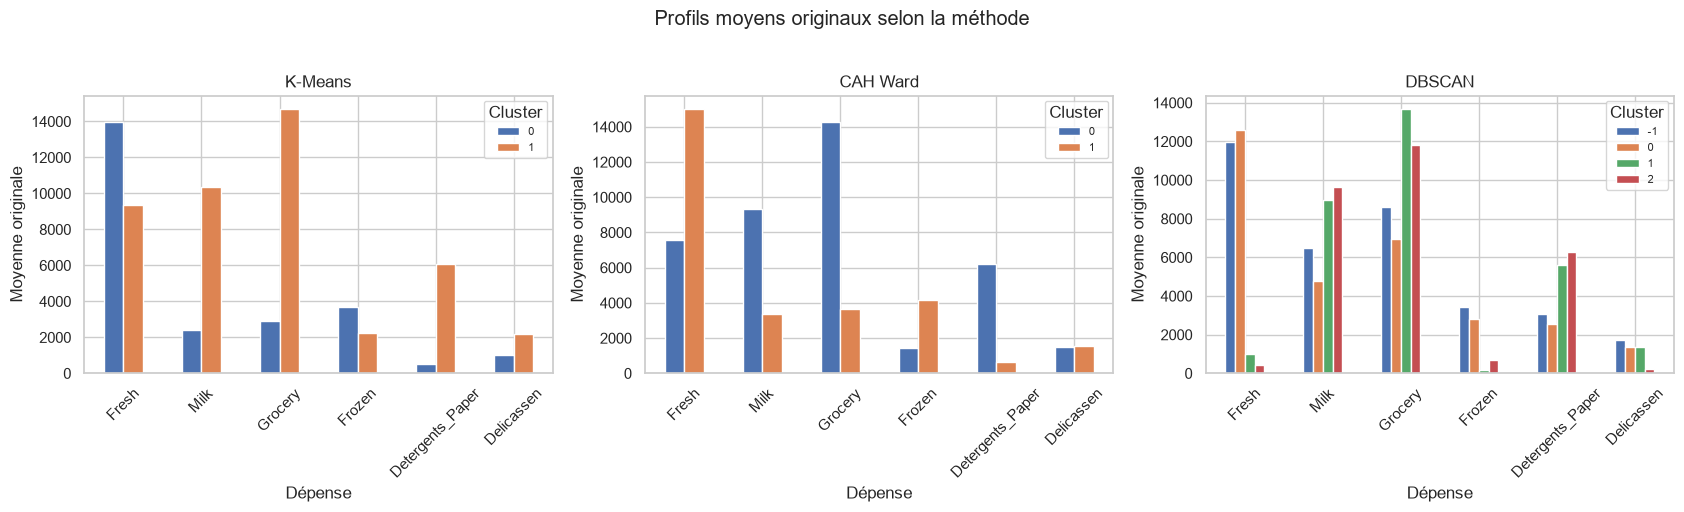

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharey=False)
for ax, method in zip(axes, ['K-Means', 'CAH Ward', 'DBSCAN']):
    part = profiles[profiles['Méthode'] == method].set_index('Cluster')[FEATURES].T
    part.plot(kind='bar', ax=ax)
    ax.set_title(method); ax.set_xlabel('Dépense'); ax.set_ylabel('Moyenne originale'); ax.tick_params(axis='x', rotation=45); ax.legend(title='Cluster', fontsize=8)
fig.suptitle('Profils moyens originaux selon la méthode', y=1.02)
fig.tight_layout(); fig.savefig(figures_dir / '18_profiles_methods_original.png', dpi=180, bbox_inches='tight'); plt.show(); plt.close(fig)

## 7. Conclusion et validation

La méthode proposée doit tenir compte simultanément de la séparation, de la couverture, de la stabilité des effectifs et de l'interprétabilité commerciale. DBSCAN n'est pas avantagé par une silhouette calculée sur un sous-ensemble si ce sous-ensemble est trop réduit.

In [11]:
assert len(best_cah_labels) == len(X) and pd.Series(best_cah_labels).notna().all()
assert len(chosen_dbscan_labels) == len(X)
assert int(kmeans_sizes.sum()) == len(X) and int(cah_sizes.sum()) == len(X)
assert all(Path(p).exists() for p in [tables_dir / 'cah_search_metrics.csv', tables_dir / 'dbscan_grid_metrics.csv', tables_dir / 'comparison_kmeans_cah_dbscan.csv', tables_dir / 'cluster_profiles_all_methods_original.csv'])
print('VALIDATION : OK')
print(f'CAH : K={best_cah_k}, silhouette={cah_results.loc[cah_results["K"] == best_cah_k, "Silhouette"].iloc[0]:.4f}, 440 points évalués.')
print(f'DBSCAN : {int(chosen_dbscan_row["Nombre_clusters"])} clusters, {chosen_dbscan_row["Bruit_pct"]:.2f}% bruit, {int(chosen_dbscan_row["Points_evalues"])} points pour la silhouette.')
print('Conclusion à lire avec les tableaux : aucune méthode ne doit être déclarée meilleure sur la silhouette seule lorsque les ensembles évalués diffèrent.')

VALIDATION : OK
CAH : K=2, silhouette=0.2585, 440 points évalués.
DBSCAN : 3 clusters, 52.27% bruit, 210 points pour la silhouette.
Conclusion à lire avec les tableaux : aucune méthode ne doit être déclarée meilleure sur la silhouette seule lorsque les ensembles évalués diffèrent.
